In [6]:
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt

from anndata import AnnData

In [2]:
plt.rcParams['font.family'] = 'Arial'       # e.g. 'Arial', 'DejaVu Sans', 'Helvetica'
plt.rcParams['font.size'] = 6              # base font size
plt.rcParams['axes.titlesize'] = 6
plt.rcParams['axes.labelsize'] = 6


In [3]:
cdata = sc.read_h5ad("./adata_marker_genes_normalized_log1p.h5ad")

In [7]:
def remove_unknown_genes(adata: AnnData, markers: dict) -> dict[np.ndarray] | np.ndarray:
    def _remove_unknown_genes(adata, markers: np.array) -> np.array:
        mask = np.isin(markers, adata.var_names)
        return markers[mask]

    if isinstance(markers, (list, np.ndarray)):
        return _remove_unknown_genes(adata, np.array(markers))
    
    if isinstance(markers, dict):
        new_marker_dict = {}
        for celltype in markers.keys():
            new_marker_dict[celltype] = _remove_unknown_genes(adata, np.array(markers[celltype]))
        return new_marker_dict


In [8]:
map_cell_names = {
    'CD14 Mono': 'CD14 Monocyte',
    'CD16 Mono': 'CD16 Monocyte',
    'cDC': 'cDC',
    'pDC': 'pDC',
    'B Naive': 'Naive B cell',
    'B Intermediate/Memory': 'Intermediate B cell',
    'CD4 Naive': 'CD4 Naive T cell',
    'CD4 Memory': 'CD4 Memory T cell',
    'CD8 Naive': 'CD8 Naive T cell',
    'CD8 Memory': 'CD8 Memory T cell',
    'Treg': 'Treg',
    'MAIT': 'MAIT',
    'ILC': 'ILC',
    'NKT': 'NKT',
    'CD56-bright NK': 'NK CD56hi',
    'CD56-dim NK': 'NK CD56low',
    'other': 'Granulocyte',
    'Plasmablast': 'Plasmablast',
    'Platelet': 'Platelet',
    'HSPC': 'HSPC',
    
}

In [9]:
cdata.obs.loc[:, "cell_type_refined2"] = cdata.obs.cell_type_refined.map(map_cell_names)

In [10]:
markers_final = {
    "Plasmablast": ["XBP1", "PRDM1"],
    "Naive B cell +": ["BTG1", "CXCR4", "IL4R"],
    "Naive B cell -": ["CD24"],
    "Memory B cell": ["IGHA1"],
    "Treg": ["FOXP3", "IL2RA"],
    "CD4 / CD8 T cell": ["CCR7", "SELL", "LEF1"],
    "CD4 T cell": ["CD4"],
    "CD4 Memory T cell": ["CD27"],
    "CD8 T cell": ["CD8A", "CD8B"],
    "CD8 Memory T cell": ["ITGB1"],
    "MAIT": ["SLC4A10", "KLRB1"],
    # "NK": ["CD3E", "CD3D", "NCAM1", "FCGR3A", "KLRC1", "KLRC2", "FCER1G", "GZMB", "GZMK"],
    "NKT": ["CD69", "CXCR3"],
    "ILC": ["FCER1G"],
    'NK cell': ['NKG7', 'KLRD1', 'GNLY', 'KLRF1', 'GZMA'],
    'CD56hi NK cell': ["NCAM1", "KLRC1"],
    'CD56low NK cell': ["FCGR3A"],
    'cDC': ['XCR1', 'FLT3', 'HLA-DRA'],
    'pDC': ['IRF8', 'CLEC4C', 'IL3RA'],
    "CD14 Mono": ['CD14', 'VCAN', 'S100A8', 'S100A9'],
    "CD16 Mono": ['FCGR3A', 'LST1', 'TCF7L2'],
    'Granulocyte': ["ITGAM", "FCER1A", "CCR3"],
    "HSPC": ["CD34"],
}

_markers_final = remove_unknown_genes(cdata, markers_final)

In [11]:
all_markers_final = {
    "B cell": ["CD19", "CD79A", "CD79B", "MS4A1", "IGHM"],
    "Naive B cell": ["IL4R"],
    "Plasmablast": ["PRDM1"],
    "T cell": ["CD3D", "CD3E"],
    "CD4 / CD8 T cell": ["CCR7", "SELL", "LEF1"],
    "CD4 T cell": ["CD4"],
    "CD8 T cell": ["CD8A", "CD8B"],
    "CD4 / CD8 Memory T cell": ["ITGB1"],
    "Treg": ["FOXP3", "IL2RA"],
    "MAIT": ["SLC4A10", "KLRB1"],
    "ILC": ["FCER1G"],
    "NK": ["NKG7", "KLRD1", "GNLY", "KLRF1", "GZMA"],
    "NK CD56hi": ["NCAM1", "KLRC1"],
    "NK CD56low": ["FCGR3A"],
    "cDC": ["XCR1", "FLT3", "HLA-DRA"],
    "pDC": ["IRF8", "CLEC4C", "IL3RA"],
    "CD14 Mono": ["CD14", "VCAN", "S100A8", "S100A9"],
    "CD16 Mono": ["FCGR3A", "LST1", "TCF7L2"],
    "Granulocyte": ["ITGAM", "FCER1A", "CCR3"],
    "HSPC": ["CD34"],
}

_all_markers_final = remove_unknown_genes(cdata, all_markers_final)

In [12]:
cell_type_order = [
    "Naive B cell",
    "Intermediate B cell",
    "Plasmablast",
    "CD4 Naive T cell",
    "CD4 Memory T cell",
    "CD8 Naive T cell",
    "CD8 Memory T cell",
    "Treg",
    "MAIT",
    "ILC",
    "NKT",
    "NK CD56hi",
    "NK CD56low",
    "cDC",
    "pDC",
    "CD14 Monocyte",
    "CD16 Monocyte",
    "Granulocyte",
    "HSPC",
]

findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font f

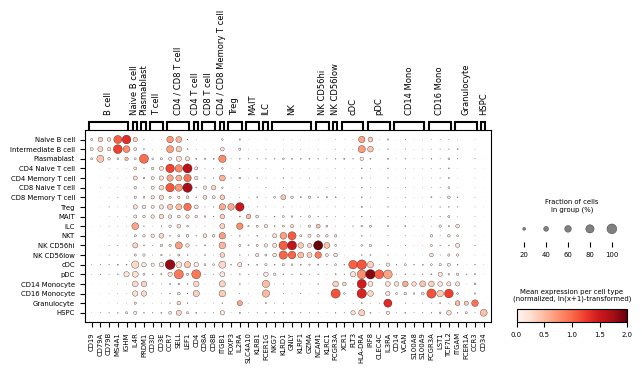

In [14]:
dp = sc.pl.dotplot(
    cdata[cdata.obs.cell_type_refined2 != "Platelet"],
    var_names=_all_markers_final,
    groupby="cell_type_refined2",
    categories_order=cell_type_order,
    figsize=(7, 2.5),
    return_fig=True,
    show=False,
    colorbar_title="Mean expression per cell type\n(normalized, ln(x+1)-transformed)"
)

scale_factor = 0.25

ax = dp.get_axes()['mainplot_ax']
for coll in ax.collections:
    sizes = coll.get_sizes()
    if sizes.size:
        coll.set_sizes(sizes * scale_factor)

leg_ax = dp.get_axes().get('size_legend_ax', None)
if leg_ax is not None:
    for coll in leg_ax.collections:
        sizes = coll.get_sizes()
        if sizes.size:
            coll.set_sizes(sizes * scale_factor)

gene_group_ax = dp.get_axes().get("gene_group_ax")
for line in gene_group_ax.lines:
    line.set_linewidth(0.1) 

if True:
    plt.savefig(
        "./cell_type_markers.svg",
        bbox_inches="tight",
        pad_inches=0,
        transparent=True,
    )
plt.show()